# 02 · Rótulos e análise exploratória

**Objetivo:** juntar rótulos e metadados à tabela de features e entender os dados antes de modelar.

**Decisões de projeto:**
- **Este notebook não seleciona features.** A remoção de features correlacionadas e a seleção por distância de separação ficam **dentro do Pipeline** do notebook 03, ajustadas só com os dados de treino de cada fold. Fazer a seleção aqui, com o dataset inteiro, deixaria informação do teste influenciar o modelo (vazamento de dados). Aqui a análise é apenas exploratória.
- **Os rótulos são configuráveis:**
  - `ESQUEMA = "artigo"` usa 3 classes. Os rolamentos com danos múltiplos são rotulados pelo dano dominante (seção 7.4 do artigo): KB23 e KB24 como anel interno, KB27 como anel externo.
  - `ESQUEMA = "4classes"` coloca os rolamentos KB numa classe própria de danos múltiplos.
- **Nenhum rolamento é descartado aqui.** Os conjuntos de cada experimento (Tabela 10, com os KB, todos os rolamentos reais) são escolhidos no notebook 03. Assim, o mesmo arquivo de saída serve a todos os experimentos.

## 1. Configuração e leitura

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

import rolamentos as R

PASTA_DADOS = Path("dados")
ARQUIVO_FEATURES = Path("features.csv")
ESQUEMA = "4classes"  # "artigo" (3 classes) ou "4classes"
ARQUIVO_SAIDA = Path(f"dataset_rotulado_{ESQUEMA}.csv")

df = R.adicionar_rotulos(pd.read_csv(ARQUIVO_FEATURES), esquema=ESQUEMA)
print(df.shape)

(1600, 100)


## 2. Rolamentos por origem e classe
A tabela mostra como cada rolamento foi rotulado. Vale conferir duas coisas:
- os danos **artificiais** aos rolamento foram desconsiderados nesse projeto, visto que nao obtiveram bom resultado para diferenciação dos rolamentos.
- o balanceamento: há mais rolamentos com dano real do que saudáveis.

In [2]:
tabela = (df.groupby(["origem", "classe_nome", "rolamento"]).size()
            .rename("amostras").reset_index())
display(tabela.groupby(["origem", "classe_nome"])
              .agg(rolamentos=("rolamento", ", ".join), amostras=("amostras", "sum")))

rolamentos  amostras
origem        classe_nome                                               
real          anel_externo        KA04, KA15, KA16, KA22, KA30       400
              anel_interno  KI04, KI14, KI16, KI17, KI18, KI21       480
real_multiplo multiplo                        KB23, KB24, KB27       240
saudavel      saudavel      K001, K002, K003, K004, K005, K006       480

## 3. Efeito da condição de operação

Este é o ponto mais importante da análise. O **rms da corrente** depende muito do torque (M01 contra M07), e a rotação muda todas as frequências características. Se o efeito da condição for maior que o efeito do dano, um modelo treinado com as 4 condições misturadas aprende a condição em vez do defeito.

Por isso o notebook 03 avalia a condição 0 (`N15_M07_F10`, igual ao artigo) separadamente e depois as 4 condições juntas, com o erro mostrado por condição.

**Obs.:**<br>
Pelos dados o RMS da corrente mede a carga do motor, não o dano.<br>
As classes com dano tendem a ter RMS da vibração mais alto que a saudável.

| No. | Rotational speed [rpm] | Load Torque3 [Nm] | Radial force [N] | Name of Setting |
|-----|------------------------|-------------------|------------------|-----------------|
| 0   | 1500                   | 0.7               | 1000             | N15_M07_F10     |
| 1   | 900                    | 0.7               | 1000             | N09_M07_F10     |
| 2   | 1500                   | 0.1               | 1000             | N15_M01_F10     |
| 3   | 1500                   | 0.7               | 400              | N15_M07_F04     |

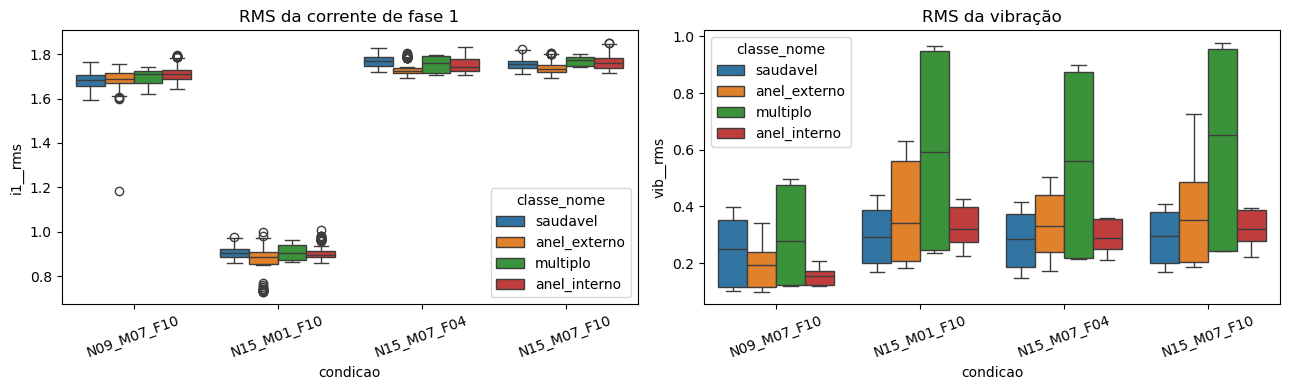

In [3]:
fig, eixos = plt.subplots(1, 2, figsize=(13, 4))
sns.boxplot(data=df, x="condicao", y="i1__rms", hue="classe_nome", ax=eixos[0])
eixos[0].set_title("RMS da corrente de fase 1")
sns.boxplot(data=df, x="condicao", y="vib__rms", hue="classe_nome", ax=eixos[1])
eixos[1].set_title("RMS da vibração")
for ax in eixos:
    ax.tick_params(axis="x", rotation=20)
plt.tight_layout()

## Frequências Características de Defeitos em Rolamentos

**BPFO (*Ball Pass Frequency, Outer race*):** frequência com que uma esfera passa por um ponto fixo do anel externo.  
**BPFI (*Ball Pass Frequency, Inner race*):** frequência com que uma esfera passa por um ponto fixo do anel interno.

Um defeito localizado gera um impacto a cada passagem de esfera, excitando ressonâncias de alta frequência. A **demodulação** — realizada por meio de um filtro passa-banda, seguido do módulo da transformada de Hilbert — permite recuperar a taxa de repetição dos impactos:

- **BPFO ≈ 3,05 · fr** — defeito no anel externo;
- **BPFI ≈ 4,95 · fr** — defeito no anel interno.

### Exemplo do funcionamento do experimento:
![Como ler o espectro de envelope](como_ler_espectro_envelope.png)

**Obs.:**<br>No anel interno, o defeito gira junto com o eixo, 25 voltas por segundo. Em cada volta ele passa pela parte do rolamento que faz força, onde as pancadas são fortes, e pela parte que quase não faz força, onde as pancadas são fracas. As pancadas ficam fortes e fracas, alternando 25 vezes por segundo, e essa alternância aparece no espectro como os picos a ±25 Hz.<br>
No anel externo, o defeito fica parado no mesmo lugar. As pancadas têm sempre a mesma força, e sem alternância não há picos a ±25 Hz.<br>



## Validação das Frequências Características

O gráfico (abaixo) compara um rolamento saudável, um com defeito no anel externo e outro com defeito no anel interno, todos na condição 0. As linhas tracejadas indicam as frequências características BPFO e BPFI.

Essa comparação permite verificar se as features `vib__env_bpfo_*` e `vib__env_bpfi_*` representam adequadamente as frequências de defeito. Além disso, a análise constitui um teste da frequência de amostragem adotada:


F_s = 64,000 {Hz}


Com uma frequência de amostragem incorreta, os picos espectrais podem não coincidir com as linhas de referência, comprometendo a identificação das frequências características.

**Obs.:**<br>
Em **K001 (saudável).** Não há nada nas linhas tracejadas, como esperado. Mas o espectro **não é plano**: aparecem picos fortes em ≈ 52, 105, 157, 210 e 262 Hz, sempre em pares próximos (≈ 100/105, 152/157…). Como estão num rolamento saudável, esses picos vêm da bancada: o motor, o inversor ou o acoplamento. **São o “ruído de fundo” do equipamento**, e vão aparecer em todos os rolamentos. Isso também explica por que as features só medem a amplitude exatamente em BPFO e BPFI, e não “o maior pico do espectro”.<br>

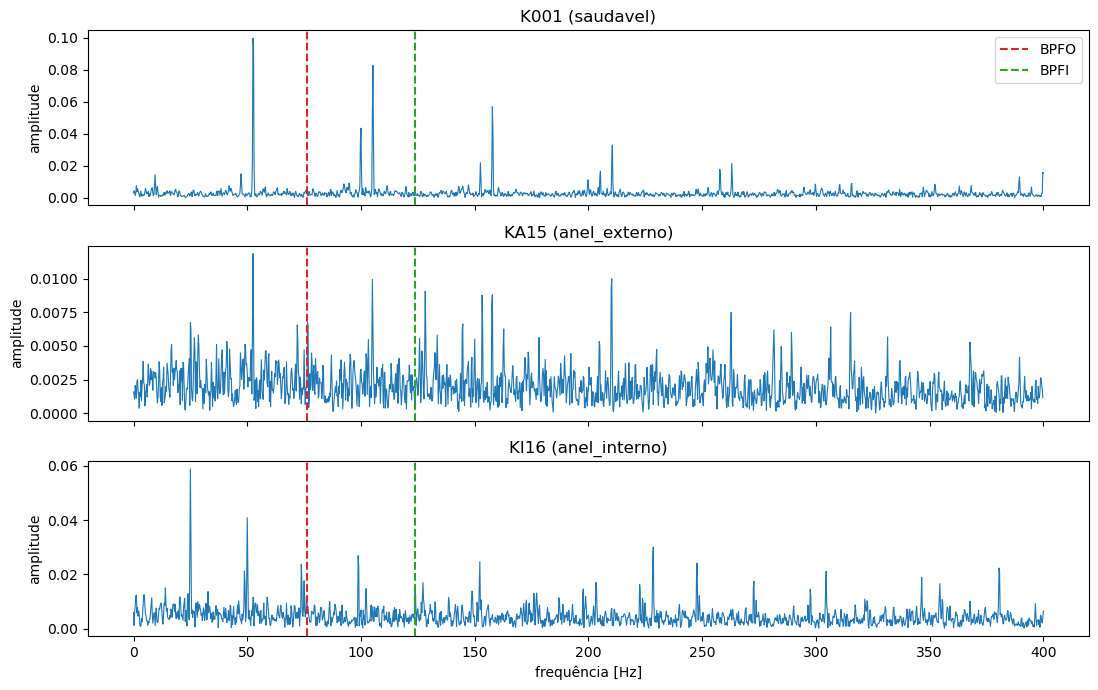

In [4]:
exemplos = {"saudavel": "K001", "anel_externo": "KA15", "anel_interno": "KI16"}
fr = 1500 / 60
fig, eixos = plt.subplots(len(exemplos), 1, figsize=(11, 7), sharex=True)
for ax, (nome, rol) in zip(eixos, exemplos.items()):
    arquivo = PASTA_DADOS / rol / f"N15_M07_F10_{rol}_1.mat"
    if not arquivo.exists():
        ax.set_title(f"{rol}: arquivo não encontrado"); continue
    freqs, amp = R.espectro_envelope(R.ler_mat(arquivo)["vibration_1"])
    faixa = freqs < 400
    ax.plot(freqs[faixa], amp[faixa], lw=0.8)
    for defeito, cor in (("bpfo", "C3"), ("bpfi", "C2")):
        ax.axvline(fr * R.FATORES_DEFEITO[defeito], ls="--", c=cor, label=defeito.upper())
    ax.set_title(f"{rol} ({nome})"); ax.set_ylabel("amplitude")
eixos[0].legend(); eixos[-1].set_xlabel("frequência [Hz]")
plt.tight_layout()

## 5. Redundância entre features (exploratório)
O mapa de correlação mostra blocos de features quase idênticas, como rms, desvio e raiz da PSD, ou pico, pico a pico e fator de crista. A remoção de verdade é feita por `RemoverCorrelacionadas` dentro do pipeline. Aqui só contamos quantas features sobrariam com |r| < 0,95 para ter uma ideia.

A remoção é calculada **separadamente por sensor**. O pipeline também roda separado nos experimentos MCS e Vibração.

i1+i2     : 58 features -> 24 após remover |r| >= 0,95
vib       : 30 features -> 18 após remover |r| >= 0,95
i1+i2+vib : 88 features -> 42 após remover |r| >= 0,95


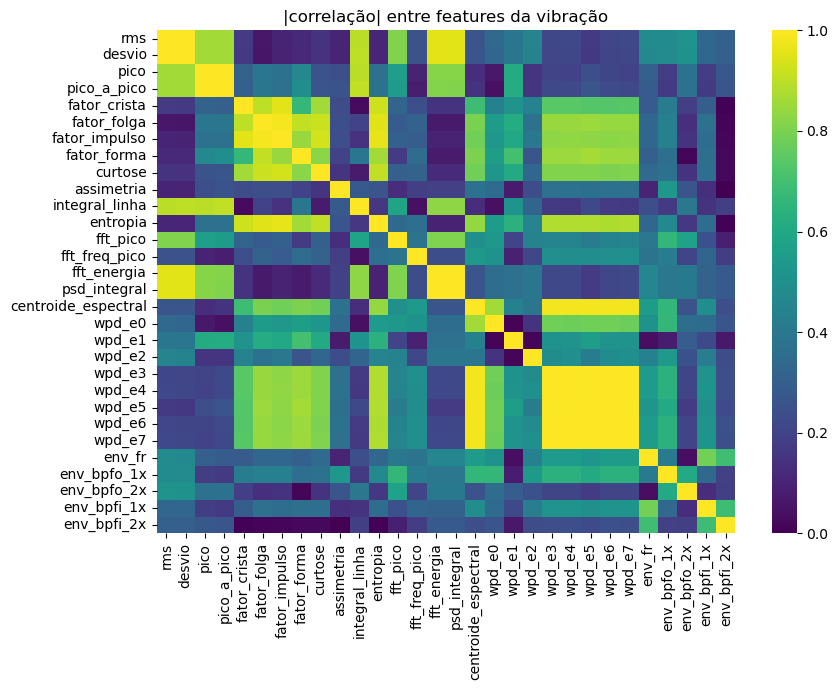

In [5]:
for sensores in R.GRUPOS_SENSORES.values():
    cols = R.colunas_features(df, sensores)
    restantes = R.RemoverCorrelacionadas(0.95).fit(df[cols].fillna(df[cols].median())).get_support().sum()
    print(f"{'+'.join(sensores):10s}: {len(cols)} features -> {restantes} após remover |r| >= 0,95")

cols_vib = R.colunas_features(df, ("vib",))
plt.figure(figsize=(9, 7))
sns.heatmap(df[cols_vib].corr().abs(), cmap="viridis", vmin=0, vmax=1,
            xticklabels=[c.split("__")[1] for c in cols_vib],
            yticklabels=[c.split("__")[1] for c in cols_vib])
plt.title("|correlação| entre features da vibração")
plt.tight_layout()

## 6. Distância de separação (exploratório)

### Ranking de separação das features (condição 0)

Esta tabela mostra **o quanto cada feature ajuda a distinguir as três classes** (saudável, anel externo e anel interno). Os dois critérios usam os mesmos dois ingredientes:

- **Separação:** o quanto as médias das classes ficam distantes umas das outras;
- **Dispersão:** o quanto os valores variam **dentro** de cada classe.

| `classe` | `classe_nome` | Rolamentos |
|---|---|---|
| 0 | saudavel | K001 a K006 |
| 1 | anel_externo | KA04, KA15, KA16, KA22, KA30 e KB27 |
| 2 | anel_interno | KI04, KI14, KI16, KI17, KI18, KI21, KB23 e KB24 |

| Critério | Cálculo | Efeito da dispersão |
|---|---|---|
| `artigo` | separação **+** dispersão | **aumenta** a nota |
| `razao` | separação **÷** dispersão | **diminui** a nota |

#### Fórmulas (classe `SelecaoSeparacao`)

**Notação:** $x_{ij}$ é o valor da feature $j$ na amostra $i$; $c$ e $k$ indicam classes; $N_c$ é o número de classes (aqui, 3); $n_c$ é o número de amostras da classe $c$.

**1. Normalização para [0, 1]**, para que todas as features fiquem na mesma escala:

$$\tilde{x}_{ij} = \frac{x_{ij} - \min_j}{\max_j - \min_j}$$

**2. Média e variância de cada feature dentro de cada classe:**

$$m_{c,j} = \frac{1}{n_c}\sum_{i \in c} \tilde{x}_{ij}
\qquad\qquad
s^2_{c,j} = \frac{1}{n_c}\sum_{i \in c} \left(\tilde{x}_{ij} - m_{c,j}\right)^2$$

**3. Separação** (distância entre as médias das classes, comparando todos os pares):

$$S_j = \frac{1}{N_c^2}\sum_{k=1}^{N_c}\sum_{c=1}^{N_c}\left(m_{k,j} - m_{c,j}\right)^2$$

**4. Dispersão** (variância média dentro das classes):

$$W_j = \frac{1}{N_c}\sum_{c=1}^{N_c} s^2_{c,j}$$

**5a. Critério `artigo`** (seção 7.1 do artigo). É a distância quadrática média entre as amostras de cada classe $k$ e a média de cada classe $c$:

$$d_j = \frac{1}{N_c^2}\sum_{k=1}^{N_c}\sum_{c=1}^{N_c}\frac{1}{n_k}\sum_{i \in k}\left(\tilde{x}_{ij} - m_{c,j}\right)^2 = W_j + S_j$$

A igualdade vem de $\frac{1}{n_k}\sum_{i \in k}(\tilde{x}_{ij} - m_{c,j})^2 = s^2_{k,j} + (m_{k,j} - m_{c,j})^2$. Por isso a dispersão **soma** na nota.

**5b. Critério `razao`** (estilo Fisher). A separação é **dividida** pela dispersão; $\varepsilon = 10^{-12}$ evita divisão por zero:

$$d_j = \frac{S_j}{W_j + \varepsilon}$$

**6. Nota final** (normalizada pela melhor feature):

$$\bar{d}_j = \frac{d_j}{\max_j d_j}$$

**7. Seleção:** a feature é mantida se $\bar{d}_j \geq$ `limiar` (0,7 no artigo). Se sobrarem menos de `min_features` (padrão 3), ficam as 3 de maior $\bar{d}_j$.

#### Interpretação:

Pelo passo 6, as notas são **relativas**: 1 é a melhor feature *desta tabela*, e não uma separação perfeita.

- **`artigo`**
  - **1:** feature com a maior soma $W_j + S_j$. Pode ser uma feature apenas muito espalhada ($W_j$ alto).
  - **0:** feature praticamente constante ($W_j = S_j = 0$).
- **`razao`**
  - **1:** feature com a maior razão $S_j / W_j$: classes distantes entre si e concentradas em torno da própria média. É a que melhor separa.
  - **0:** as três classes têm a mesma média ($S_j = 0$), então a feature não ajuda em nada.

**Leitura dos resultados.**
- O critério `artigo` dá notas altas às features `wpd`, que variam muito dentro de cada classe ($W_j$ alto). Também rebaixa `env_bpfi_1x`, que separa bem as classes. Por isso, o critério `razao` é o mais confiável.
- Pela `razao`, as melhores features são `env_bpfi_2x`, `env_fr` e `env_bpfi_1x`, todas ligadas ao **anel interno**.
- Não aparece nenhuma feature de **anel externo** (`env_bpfo`) nem de **corrente**. O dano no anel externo desses rolamentos é leve, e a corrente separa pouco nesta condição.

⚠️ Esta tabela é apenas exploratória. Ela usa todos os dados, então escolher colunas a partir dela causaria vazamento. A seleção real é refeita dentro de cada fold no notebook 03.

In [6]:
d0 = df[(df["condicao"] == "N15_M07_F10") & (df["origem"] != "artificial")]
cols = R.colunas_features(d0)
X0 = d0[cols].fillna(d0[cols].median())
ranking = pd.DataFrame({
    m: R.SelecaoSeparacao(metodo=m).fit(X0, d0["classe"]).distancias_ for m in ("artigo", "razao")
}, index=cols)
ranking.sort_values("razao", ascending=False).head(15).round(3)

,artigo,razao
vib__wpd_e3,0.988,1.000
vib__wpd_e4,0.993,0.996
vib__wpd_e6,1.000,0.973
vib__wpd_e7,0.985,0.971
vib__centroide_espectral,0.965,0.950
vib__wpd_e5,0.964,0.911
vib__env_bpfi_2x,0.683,0.750
vib__env_bpfi_1x,0.539,0.666
vib__wpd_e0,0.947,0.600
vib__env_fr,0.818,0.492


## 7. Salvar
O arquivo final tem features, metadados (condição, rotação, torque, força) e rótulos (`origem`, `classe`, `classe_nome`, `danificado`). É a entrada do notebook 03.

In [7]:
df.to_csv(ARQUIVO_SAIDA, index=False)
print("salvo:", ARQUIVO_SAIDA, df.shape)

salvo: dataset_rotulado_4classes.csv (1600, 100)


In [8]:
df

,arquivo,condicao,rolamento,medicao,rotacao_rpm,torque_nm,forca_n,segmento,i1__rms,i1__desvio,...,vib__wpd_e7,vib__env_fr,vib__env_bpfo_1x,vib__env_bpfo_2x,vib__env_bpfi_1x,vib__env_bpfi_2x,origem,classe,classe_nome,danificado
0,N09_M07_F10_K001_1,N09_M07_F10,K001,1,900,0.7,1000,0,1.656722,1.656556,...,0.121244,15.744950,9.521987,13.266914,4.740935,18.169190,saudavel,0,saudavel,0
1,N09_M07_F10_K001_2,N09_M07_F10,K001,2,900,0.7,1000,0,1.669053,1.668909,...,0.121032,17.031448,7.924775,14.099693,6.854121,19.357992,saudavel,0,saudavel,0
2,N09_M07_F10_K001_3,N09_M07_F10,K001,3,900,0.7,1000,0,1.677920,1.677769,...,0.123043,17.719663,8.328271,12.196246,7.660825,17.694461,saudavel,0,saudavel,0
3,N09_M07_F10_K001_4,N09_M07_F10,K001,4,900,0.7,1000,0,1.682914,1.682794,...,0.120371,15.881922,8.033620,10.881797,8.081305,16.938854,saudavel,0,saudavel,0
4,N09_M07_F10_K001_5,N09_M07_F10,K001,5,900,0.7,1000,0,1.687410,1.687280,...,0.125628,16.825546,7.763651,11.660633,6.621630,17.063454,saudavel,0,saudavel,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1595,N15_M07_F10_KI21_16,N15_M07_F10,KI21,16,1500,0.7,1000,0,1.850392,1.848496,...,0.012232,27.296251,17.845300,12.770627,22.731350,19.636593,real,2,anel_interno,1
1596,N15_M07_F10_KI21_17,N15_M07_F10,KI21,17,1500,0.7,1000,0,1.841524,1.840069,...,0.012398,27.809261,21.071294,10.799375,22.685219,19.313768,real,2,anel_interno,1
1597,N15_M07_F10_KI21_18,N15_M07_F10,KI21,18,1500,0.7,1000,0,1.851249,1.849409,...,0.011811,28.226172,17.159657,13.302826,22.116150,20.036476,real,2,anel_interno,1
1598,N15_M07_F10_KI21_19,N15_M07_F10,KI21,19,1500,0.7,1000,0,1.842176,1.840682,...,0.014171,28.023303,18.401649,16.471876,21.236947,19.858538,real,2,anel_interno,1
